# **House Price Prediction – Tunned Models and Feature Selection Experiments**
- **Author:** Abdallah Idris Benseghir
- **Year:** 2026
- **Month:** November
- **Project:** House Price Prediction

#### **Dataset**: [House Prices – Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)

#### **Notebook Description**

**File:** `05_Tuuned_Models_and_Feature_Selection_Experiments.ipynb`

This notebook investigates regression model performance through two experimental stages. The first stage evaluates regression models using all available features, while the second examines the impact of removing low-correlation features on model performance.

##### **Stage 1 — Hyperparameter Tuning + Cross-Validation**
- Load and prepare the cleaned training and testing datasets.
- Separate independent features and the target variable.
- Train Linear Regression as a reference model.
- Apply Ridge Regression with GridSearchCV and 5-fold cross-validation.
- Apply Lasso Regression with GridSearchCV and 5-fold cross-validation.
- Optimize Random Forest using RandomizedSearchCV and 5-fold cross-validation.
- Evaluate models using MAE, MSE, RMSE and R².
- Compare model performance.

##### **Stage 2 — Feature Selection with Hyperparameter Tuning + Cross-Validation**
- Load previously identified low-correlation feature names.
- Remove the identified features from training and testing datasets.
- Retrain Linear Regression as a reference model.
- Apply Ridge Regression with GridSearchCV and 5-fold cross-validation.
- Apply Lasso Regression with GridSearchCV and 5-fold cross-validation.
- Optimize Random Forest using RandomizedSearchCV and 5-fold cross-validation.
- Apply hyperparameter tuning using GridSearchCV.
- Evaluate and compare model performance after feature removal.

##### **Output**

The notebook provides performance comparisons between regression models trained with all features and models trained after low-correlation feature removal.

**Note:** The purpose of this experiment is to investigate whether removing weakly correlated features improves regression performance and to identify promising models for house price prediction.

#### **Stage 1 — Hyperparameter Tuning + Cross-Validation**

##### **Section 1 –  Import libraries**

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting and cross-validation
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor

# Pipeline
from sklearn.pipeline import Pipeline

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

##### **Section 2 – Load dataset**

In [2]:
# Define dataset paths
train = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_train.csv"
test = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\clean_test.csv"

# Load datasets
train_df = pd.read_csv(train)
test_df = pd.read_csv(test)

# Display training dataset dimensions
print("Training Dataset Shape:", train_df.shape)
# Display first five rows
display(train_df.head())

# Display testing dataset dimensions
print("\nTesting Dataset Shape:", test_df.shape)
# Display first five rows
display(test_df.head())

Training Dataset Shape: (1103, 228)


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,255,20,70.0,8400,1,4,1,5,6,1957,...,0,0,0,1,0,0,0,0,1,0
1,1067,60,59.0,7837,1,3,1,6,7,1993,...,0,0,0,1,0,0,0,0,1,0
2,800,50,60.0,7200,1,4,1,5,7,1937,...,0,0,0,1,0,0,0,0,1,0
3,381,50,50.0,5000,1,4,1,5,6,1924,...,0,0,0,1,0,0,0,0,1,0
4,304,20,70.0,9800,1,4,1,5,7,1972,...,0,0,0,1,1,0,0,0,0,0



Testing Dataset Shape: (275, 228)


,Id,MSSubClass,LotFrontage,LotArea,Street,LotShape,LandSlope,OverallQual,OverallCond,YearBuilt,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,893,20,70.0,8414,1,4,1,6,8,1963,...,0,0,0,1,0,0,0,0,1,0
1,1106,60,98.0,12256,1,3,1,8,5,1994,...,0,0,0,1,0,0,0,0,1,0
2,414,30,56.0,8960,1,4,1,5,6,1927,...,0,0,0,1,0,0,0,0,1,0
3,523,50,50.0,5000,1,4,1,6,7,1947,...,0,0,0,1,0,0,0,0,1,0
4,1037,20,89.0,12898,1,3,1,9,5,2007,...,0,0,0,1,0,0,0,0,1,0


##### **Section 3 – Data Separation**

In [3]:
# Separate independent features (X) and dependent target (y)

# Training dataset
X_train = train_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_train = train_df["SalePrice"]

# Testing dataset
X_test = test_df.drop(columns=["SalePrice", "Id"], errors="ignore")
y_test = test_df["SalePrice"]

# Display shapes
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (1103, 226)
y_train Shape: (1103,)
X_test Shape: (275, 226)
y_test Shape: (275,)


##### **Section 4 – Create an evaluation function**

In [4]:
def evaluate_model(model, X_test, y_test):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

##### **Section 5 – Linear Regression — Reference Model**

In [5]:
# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

# Evaluate model
lr_results = evaluate_model(lr_model, X_test, y_test)

print("\nLinear Regression Performance")
for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Linear Regression trained successfully!

Linear Regression Performance
MAE: 20447.6334
MSE: 987719970.8431
RMSE: 31428.0125
R2 Score: 0.8726


##### **Section 6 – Ridge Regression Hyperparameter Tuning**

In [6]:
# Create pipeline
ridge_pipeline = Pipeline([
    ("model", Ridge())
])

# Hyperparameters to test
ridge_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_ridge.fit(X_train, y_train)

print("Best Ridge Parameters:", grid_search_ridge.best_params_)
print("Best Ridge cross-validation R²:", f"{grid_search_ridge.best_score_:.2f}")

Best Ridge Parameters: {'model__alpha': 10}
Best Ridge cross-validation R²: 0.79


In [7]:
# Get best Ridge model
best_ridge = grid_search_ridge.best_estimator_

# Evaluate model
ridge_results = evaluate_model(best_ridge, X_test, y_test)

print("\nRidge Regression Performance")
for metric, value in ridge_results.items():
    print(f"{metric}: {value:.4f}")


Ridge Regression Performance
MAE: 19497.9619
MSE: 1029799794.3418
RMSE: 32090.4938
R2 Score: 0.8671


##### **Section 7 – Lasso Regression Hyperparameter Tuning**

In [8]:
# Create pipeline
lasso_pipeline = Pipeline([
    ("model", Lasso(max_iter=20000))
])

# Hyperparameters to test
lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_lasso = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_lasso.fit(X_train, y_train)

print("Best Lasso Parameters:", grid_search_lasso.best_params_)
print("Best Lasso CV R²:", f"{grid_search_lasso.best_score_:.2f}")

Best Lasso Parameters: {'model__alpha': 100}
Best Lasso CV R²: 0.78


In [9]:
# Get best Lasso model
best_lasso = grid_search_lasso.best_estimator_

# Evaluate model
lasso_results = evaluate_model(best_lasso, X_test, y_test)

print("\nLasso Regression Performance")
for metric, value in lasso_results.items():
    print(f"{metric}: {value:.4f}")


Lasso Regression Performance
MAE: 18227.4846
MSE: 909515293.7305
RMSE: 30158.1713
R2 Score: 0.8827


##### **Section 9 – Random Forest Regressor Hyperparameter Tuning**

In [10]:
# Initialize Random Forest
rf = RandomForestRegressor(random_state=42, n_jobs=1)

# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.5, 0.7, 1.0]
}

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train using training data only
random_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(random_search.best_params_)

# Best model
best_rf = random_search.best_estimator_

# Predict testing data
y_pred = best_rf.predict(X_test)

# Evaluate model
rf_results = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2 Score": r2_score(y_test, y_pred)
}

print("\nRandom Forest - Tuned Model Performance")

for metric, value in rf_results.items():
    print(f"{metric}: {value:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 30}

Random Forest - Tuned Model Performance
MAE: 17554.9724
MSE: 870218264.3225
RMSE: 29499.4621
R2 Score: 0.8877


##### **Section 10 – Models Comparison**

In [11]:
# Combine results
comparison_df = pd.DataFrame({
    "Linear Regression": lr_results,
    "Ridge Regression": ridge_results,
    "Lasso Regression": lasso_results,
    "Random Forest Regressor": rf_results
}).T

# Sort by R² score
comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(comparison_df.round(4))

,MAE,MSE,RMSE,R2 Score
Random Forest Regressor,17554.9724,8.702183e+08,29499.4621,0.8877
Lasso Regression,18227.4846,9.095153e+08,30158.1713,0.8827
Linear Regression,20447.6334,9.877200e+08,31428.0125,0.8726
Ridge Regression,19497.9619,1.029800e+09,32090.4938,0.8671


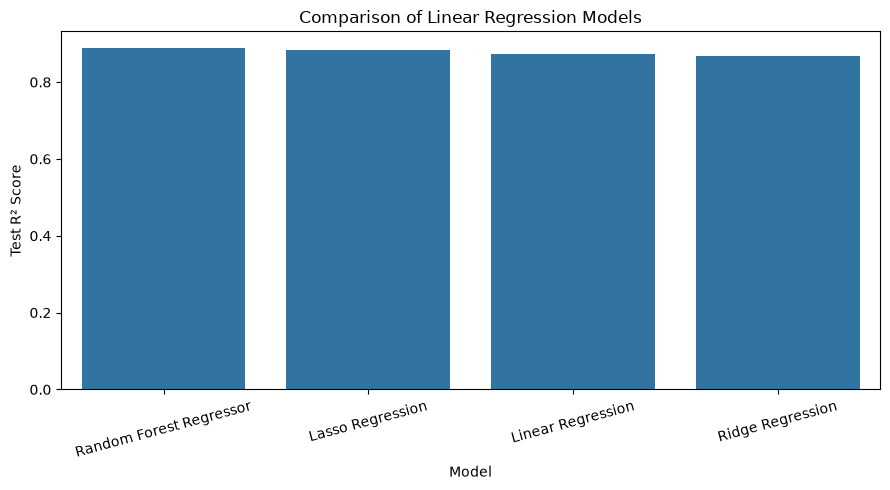

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=comparison_df.index,
    y=comparison_df["R2 Score"]
)

plt.title("Comparison of Linear Regression Models")
plt.xlabel("Model")
plt.ylabel("Test R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### **Stage 2 — Feature Selection with Hyperparameter Tuning + Cross-Validation**

##### **Section 1 – Data separation + Feature Selection**

In [13]:
# Read low-correlation feature names
feature_file = r"C:\Users\idris\OneDrive\Desktop\Master_AI\Applied_ML\Assignment 1\house-prices-advanced-regression-techniques\selected_features.txt"

with open(feature_file, "r") as file:
    selected_features = [line.strip() for line in file if line.strip()]

# Separate independent features (X) and dependent target (y)

# Training dataset
X_train = train_df.drop(columns=["SalePrice"] + selected_features, errors="ignore")
y_train = train_df["SalePrice"]

# Testing dataset
X_test = test_df.drop(columns=["SalePrice"] + selected_features, errors="ignore")
y_test = test_df["SalePrice"]

# Display shapes
print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)

print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (1103, 206)
y_train Shape: (1103,)
X_test Shape: (275, 206)
y_test Shape: (275,)


##### **Section 2 – Create an evaluation function**

In [14]:
def evaluate_model(model, X_test, y_test):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

##### **Section 3 – Linear Regression — Reference Model**

In [15]:
# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

print("Linear Regression trained successfully!")

# Evaluate model
lr_results = evaluate_model(lr_model, X_test, y_test)

print("\nLinear Regression Performance")
for metric, value in lr_results.items():
    print(f"{metric}: {value:.4f}")

Linear Regression trained successfully!

Linear Regression Performance
MAE: 21109.5664
MSE: 1022789203.5466
RMSE: 31981.0757
R2 Score: 0.8680


##### **Section 4 – Ridge Regression Hyperparameter Tuning**

In [16]:
# Create pipeline
ridge_pipeline = Pipeline([
    ("model", Ridge())
])

# Hyperparameters to test
ridge_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_ridge.fit(X_train, y_train)

print("Best Ridge Parameters:", grid_search_ridge.best_params_)
print("Best Ridge CV R²:", grid_search_ridge.best_score_)

Best Ridge Parameters: {'model__alpha': 10}
Best Ridge CV R²: 0.800375433589676


In [17]:
# Get best Ridge model
best_ridge = grid_search_ridge.best_estimator_

# Evaluate model
ridge_results = evaluate_model(best_ridge, X_test, y_test)

print("\nRidge Regression Performance")
for metric, value in ridge_results.items():
    print(f"{metric}: {value:.4f}")


Ridge Regression Performance
MAE: 19929.0336
MSE: 1059848327.3504
RMSE: 32555.3118
R2 Score: 0.8633


##### **Section 5 – Lasso Regression Hyperparameter Tuning**

In [18]:
# Create pipeline
lasso_pipeline = Pipeline([
    ("model", Lasso(max_iter=20000))
])

# Hyperparameters to test
lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# Grid Search with 5-fold cross-validation
grid_search_lasso = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and find the best parameters
grid_search_lasso.fit(X_train, y_train)

print("Best Lasso Parameters:", grid_search_lasso.best_params_)
print("Best Lasso CV R²:", grid_search_lasso.best_score_)

Best Lasso Parameters: {'model__alpha': 100}
Best Lasso CV R²: 0.7861290705280461


In [19]:
# Get best Lasso model
best_lasso = grid_search_lasso.best_estimator_

# Evaluate model
lasso_results = evaluate_model(best_lasso, X_test, y_test)

print("\nLasso Regression Performance")
for metric, value in lasso_results.items():
    print(f"{metric}: {value:.4f}")


Lasso Regression Performance
MAE: 19281.3568
MSE: 971982876.8256
RMSE: 31176.6399
R2 Score: 0.8746


##### **Section 6 – Random Forest Regressor Hyperparameter Tuning**

In [20]:
# Initialize Random Forest
rf = RandomForestRegressor(random_state=42, n_jobs=1)

# Define hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.5, 0.7, 1.0]
}

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train using training data only
random_search.fit(X_train, y_train)

# Best parameters
print("Best Parameters:")
print(random_search.best_params_)

# Best model
best_rf = random_search.best_estimator_

# Predict testing data
y_pred = best_rf.predict(X_test)

# Evaluate model
rf_results = {
    "MAE": mean_absolute_error(y_test, y_pred),
    "MSE": mean_squared_error(y_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R2 Score": r2_score(y_test, y_pred)
}

print("\nRandom Forest - Tuned Model Performance")

for metric, value in rf_results.items():
    print(f"{metric}: {value:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 20}

Random Forest - Tuned Model Performance
MAE: 18140.6301
MSE: 908158571.1586
RMSE: 30135.6694
R2 Score: 0.8828


##### **Section 7 – Models Comparison**

In [21]:
# Combine results
comparison_df = pd.DataFrame({
    "Linear Regression": lr_results,
    "Ridge Regression": ridge_results,
    "Lasso Regression": lasso_results,
    "Random Forest Regressor": rf_results
}).T

# Sort by R² score
comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(comparison_df.round(4))

,MAE,MSE,RMSE,R2 Score
Random Forest Regressor,18140.6301,9.081586e+08,30135.6694,0.8828
Lasso Regression,19281.3568,9.719829e+08,31176.6399,0.8746
Linear Regression,21109.5664,1.022789e+09,31981.0757,0.8680
Ridge Regression,19929.0336,1.059848e+09,32555.3118,0.8633


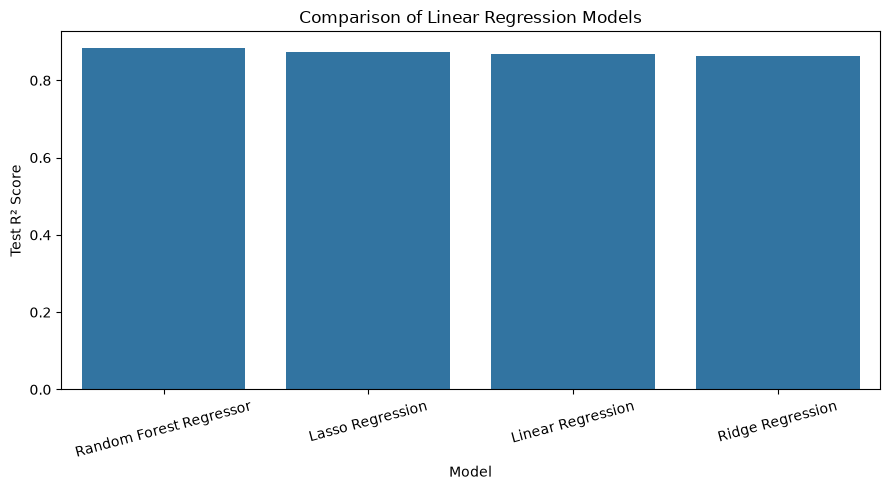

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=comparison_df.index,
    y=comparison_df["R2 Score"]
)

plt.title("Comparison of Linear Regression Models")
plt.xlabel("Model")
plt.ylabel("Test R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()